In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import pandas as pd

df = pd.read_csv(
    "/content/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpam and Ham Counts:")
print(df["label"].value_counts())

Dataset Shape: (5572, 2)

Column Names:
Index(['label', 'message'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Missing Values:
label      0
message    0
dtype: int64

Spam and Ham Counts:
label
ham     4825
spam     747
Name: count, dtype: int64


In [4]:
import re

df = df.dropna()
df = df.drop_duplicates()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

df["message"] = df["message"].apply(clean_text)

print(df.head())

  label                                            message
0   ham  go until jurong point crazy available only in ...
1   ham                            ok lar joking wif u oni
2  spam  free entry in  a wkly comp to win fa cup final...
3   ham        u dun say so early hor u c already then say
4   ham  nah i dont think he goes to usf he lives aroun...


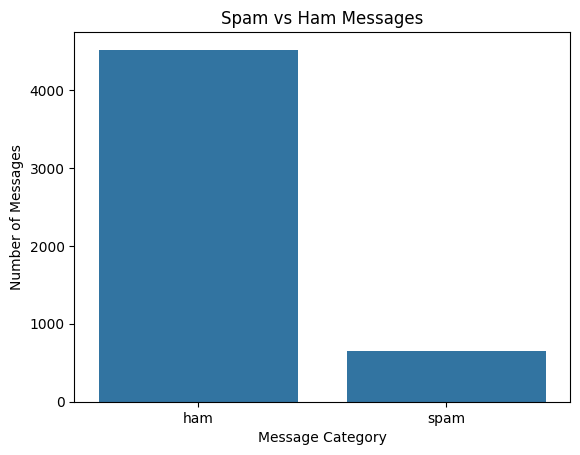

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="label")

plt.title("Spam vs Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

In [6]:
X = df["message"]
y = df["label"]

print("Input Data:")
print(X.head())

print("\nOutput Labels:")
print(y.head())

Input Data:
0    go until jurong point crazy available only in ...
1                              ok lar joking wif u oni
2    free entry in  a wkly comp to win fa cup final...
3          u dun say so early hor u c already then say
4    nah i dont think he goes to usf he lives aroun...
Name: message, dtype: object

Output Labels:
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: object


In [7]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train_text))
print("Testing Samples:", len(X_test_text))

Training Samples: 4135
Testing Samples: 1034


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Features: (4135, 5000)
Testing Features: (1034, 5000)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "SVM": LinearSVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label="spam"
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label="spam"
        ),
        "F1 Score": f1_score(
            y_test, predictions, pos_label="spam"
        )
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)

print(results_df)

             Algorithm  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.952611   0.976744  0.641221  0.774194
1          Naive Bayes  0.970019   1.000000  0.763359  0.865801
2                  SVM  0.974855   0.956522  0.839695  0.894309
3        Decision Tree  0.949710   0.796992  0.809160  0.803030
4        Random Forest  0.972921   0.972477  0.809160  0.883333
5                  KNN  0.910058   1.000000  0.290076  0.449704


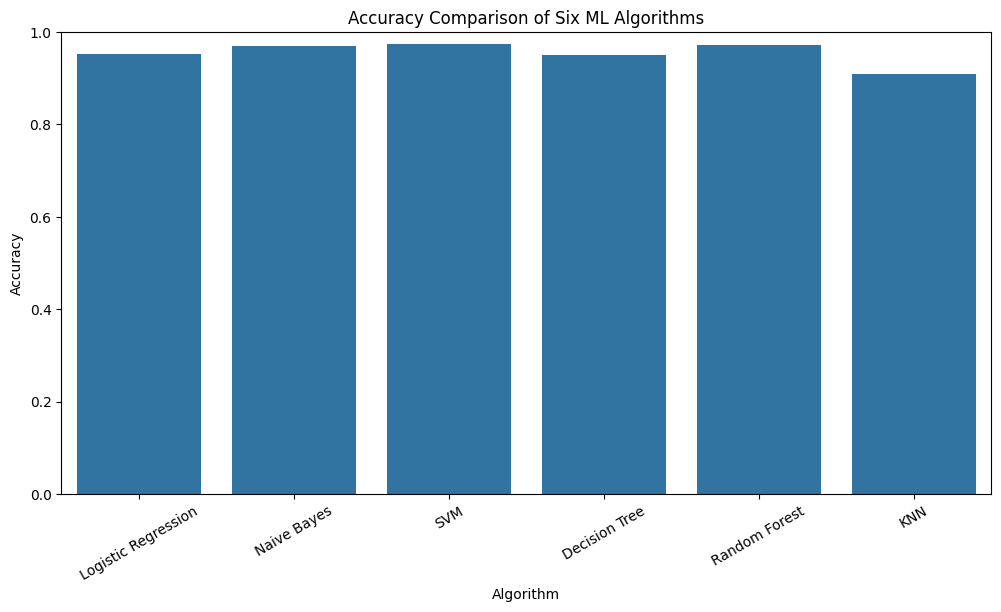

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Six ML Algorithms")
plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.show()

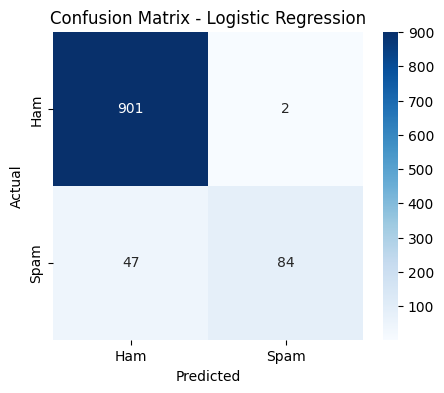

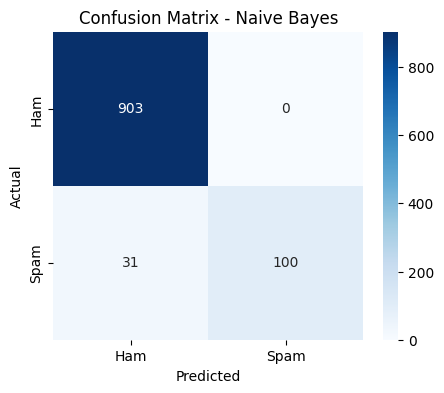

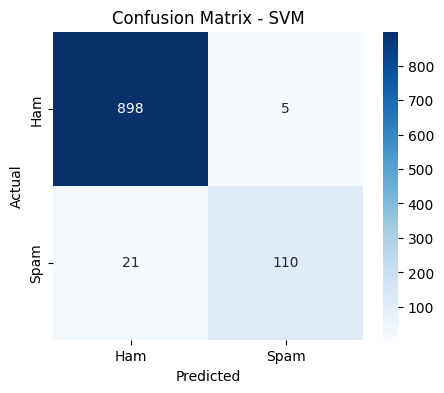

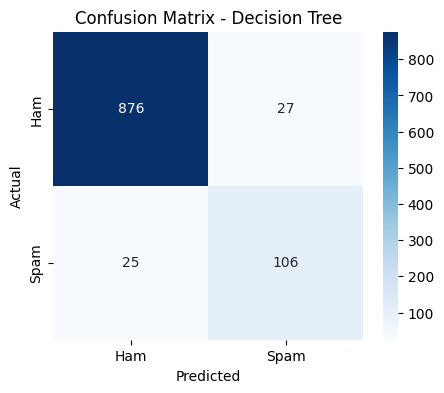

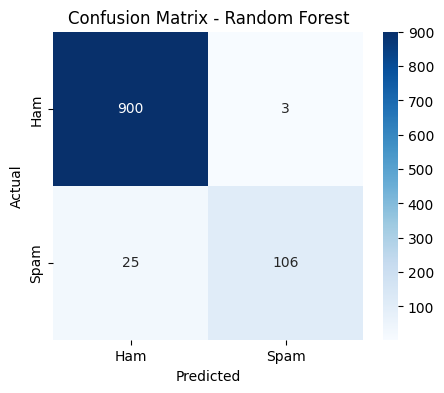

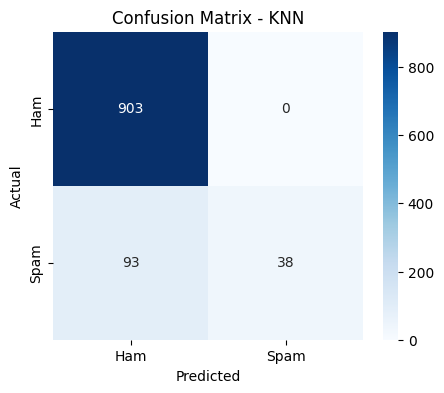

In [11]:
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

for name, model in trained_models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["ham", "spam"]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [12]:
best_name = results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]["Algorithm"]

best_model = trained_models[best_name]

print("Best Algorithm:", best_name)

Best Algorithm: SVM


In [13]:
import joblib

joblib.dump(best_model, "spam_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and Vectorizer Saved Successfully!")

Model and Vectorizer Saved Successfully!


In [14]:
%%writefile app.py

import streamlit as st
import joblib

model = joblib.load("spam_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")

st.title("SMS Spam Detection System")

st.write(
    "Enter a message to check whether it is Spam or Ham."
)

message = st.text_area("Enter your SMS message:")

if st.button("Predict"):

    if message.strip():

        message = message.lower()

        features = tfidf.transform([message])

        prediction = model.predict(features)[0]

        if prediction == "spam":
            st.error("This message is SPAM!")

        else:
            st.success("This message is HAM (Not Spam)!")

    else:
        st.warning("Please enter a message.")

Writing app.py


In [15]:
%%writefile requirements.txt

streamlit
scikit-learn
pandas
joblib

Writing requirements.txt


In [16]:
from google.colab import files

files.download("app.py")
files.download("spam_model.pkl")
files.download("tfidf_vectorizer.pkl")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>